# CIE 2 – Activity 1: Dataset Preparation

**Course:** Machine Learning (ADPC509)  
**Unit:** I – Foundations & Data Preparation  
**Marks:** 5

## 1. Dataset selection and source
This activity uses the **Diabetes dataset distributed with scikit-learn**. It contains 442 records and 10 numerical input measurements, with a continuous target representing a quantitative measure of disease progression one year after baseline. The dataset is publicly available through scikit-learn.

- Dataset documentation: https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset
- Dataset loader: `sklearn.datasets.load_diabetes`
- File type used in this notebook: CSV
- Note: the original dataset contains numerical features. To demonstrate mixed-type preparation, `bmi_category` is derived from BMI. A small number of missing values are **deliberately introduced in a working copy** to demonstrate missing-value handling; these are not claimed to be missing in the original source dataset.

In [2]:
%pip install seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler

# Load the public dataset
dataset = load_diabetes(as_frame=True)
df_original = dataset.frame.copy()

print("Original dataset shape:", df_original.shape)
display(df_original.head())
display(df_original.tail())

Original dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0
441,-0.045472,-0.044642,-0.073030,-0.081413,0.083740,0.027809,0.173816,-0.039493,-0.004222,0.003064,57.0


## 2. Create a working copy and a categorical feature

The source dataset contains 442 rows and 11 columns when the target is included. The `bmi_category` column is derived from the numerical BMI feature to demonstrate categorical analysis and encoding.

In [4]:
df = df_original.copy()
df["bmi_category"] = pd.cut(
    df["bmi"],
    bins=[-np.inf, -0.02, 0.02, np.inf],
    labels=["Low", "Medium", "High"]
)

# Introduce a few demonstration missing values in the working copy only.
df.loc[[5, 19, 44, 88, 120], "bmi"] = np.nan
df.loc[[12, 57, 101], "bmi_category"] = np.nan
df.loc[[30, 31], "bp"] = np.nan

print("Working dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
display(df.head())

Working dataset shape: (442, 12)

Column names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target', 'bmi_category']

Data types:


,Data type
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target,bmi_category
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0,High
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0,Low
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0,High
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0,Medium
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0,Low


## 3. Numerical and categorical columns; summary statistics

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
display(df[numeric_cols].describe().T)
for col in categorical_cols:
    print(f"\nFrequency counts for {col}:")
    display(df[col].value_counts(dropna=False))

Numerical columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']
Categorical columns: ['bmi_category']


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,437.0,6.114078e-05,0.047692,-0.090275,-0.034229,-0.007284,0.031517,0.170555
bp,440.0,2.292158e-04,0.047559,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612



Frequency counts for bmi_category:


bmi_category
Low       171
Medium    135
High      133
NaN         3
Name: count, dtype: int64

## 4. Missing-value analysis

In [6]:
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
    "Missing count": missing_count,
    "Missing percentage": missing_percent
})
display(missing_summary)

print("Columns without missing values:", missing_summary[missing_summary["Missing count"] == 0].index.tolist())
print("Columns requiring attention:", missing_summary[missing_summary["Missing count"] > 0].index.tolist())

,Missing count,Missing percentage
age,0,0.00
sex,0,0.00
bmi,5,1.13
bp,2,0.45
s1,0,0.00
s2,0,0.00
s3,0,0.00
s4,0,0.00
s5,0,0.00
s6,0,0.00


Columns without missing values: ['age', 'sex', 's1', 's2', 's3', 's4', 's5', 's6', 'target']
Columns requiring attention: ['bmi', 'bp', 'bmi_category']


## 5. Handle missing values

A copy is retained before cleaning. Median imputation is used for numerical columns because it is less affected by extreme values than the mean. Mode imputation is used for the categorical column. No rows or columns are deleted.

In [7]:
df_clean = df.copy()

numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns.tolist()

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values after imputation:")
display(df_clean.isna().sum().to_frame("Remaining missing values"))

Missing values after imputation:


,Remaining missing values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


## 6. Duplicate and consistency checks

In [8]:
duplicate_count = df_clean.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

# Remove only exact duplicate rows, if any.
df_clean = df_clean.drop_duplicates().copy()

# Normalize categorical labels (trim whitespace and standardize capitalization).
for col in df_clean.select_dtypes(exclude=np.number).columns:
    df_clean[col] = df_clean[col].astype(str).str.strip().str.title()

print("Shape after duplicate check:", df_clean.shape)

Duplicate rows found: 0
Shape after duplicate check: (442, 12)


## 7. Exploratory Data Analysis (EDA)

The following visualizations examine the distribution of BMI and the frequency of the derived BMI categories.

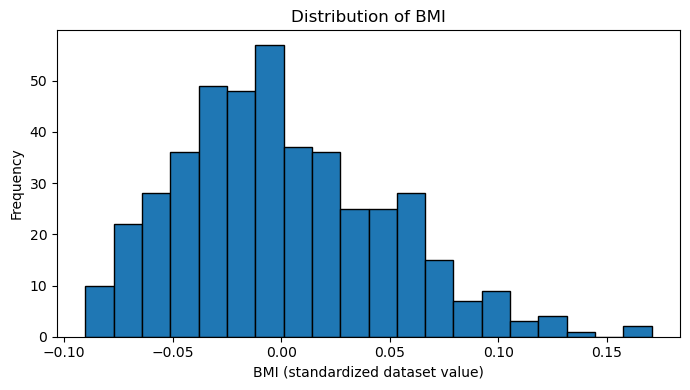

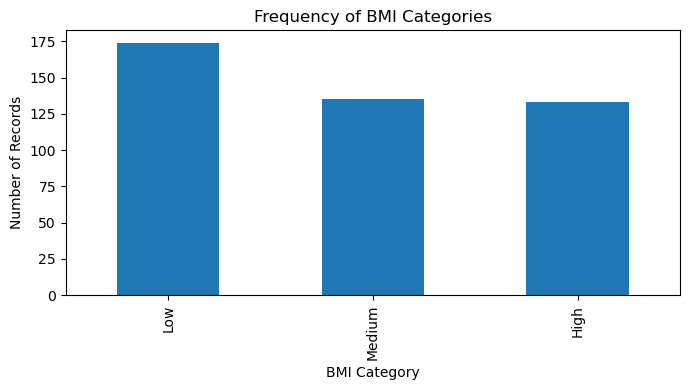

EDA observations:
1. The BMI histogram shows the spread of BMI values in the dataset.
2. The bar chart shows how records are distributed among the derived BMI categories.
3. BMI category is derived from BMI; it is not an original source column.


In [9]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["bmi"], bins=20, edgecolor="black")
plt.title("Distribution of BMI")
plt.xlabel("BMI (standardized dataset value)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
df_clean["bmi_category"].value_counts().reindex(["Low", "Medium", "High"]).plot(kind="bar")
plt.title("Frequency of BMI Categories")
plt.xlabel("BMI Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("EDA observations:")
print("1. The BMI histogram shows the spread of BMI values in the dataset.")
print("2. The bar chart shows how records are distributed among the derived BMI categories.")
print("3. BMI category is derived from BMI; it is not an original source column.")

## 8. Encode categorical features

`bmi_category` is nominal for this demonstration, so one-hot encoding is used. The original category is represented by separate binary columns.

In [10]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=["bmi_category"],
    drop_first=False,
    dtype=int
)
print("Columns after one-hot encoding:")
print(df_encoded.columns.tolist())
display(df_encoded.head())

Columns after one-hot encoding:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target', 'bmi_category_High', 'bmi_category_Low', 'bmi_category_Medium']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target,bmi_category_High,bmi_category_Low,bmi_category_Medium
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0,1,0,0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0,0,1,0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0,1,0,0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0,0,0,1
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0,0,1,0


## 9. Scale numerical features

Standardization is applied to numerical input features (mean approximately 0 and standard deviation approximately 1). The target column is not scaled, and no identifier column is scaled.

In [11]:
feature_numeric_cols = [c for c in numeric_cols if c != "target"]
scaler = StandardScaler()
df_encoded[feature_numeric_cols] = scaler.fit_transform(df_encoded[feature_numeric_cols])

display(df_encoded[feature_numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,442.0,8.037814e-18,1.001133,-2.254290,-0.784172,0.113172,0.800500,2.327895
sex,442.0,1.607563e-17,1.001133,-0.938537,-0.938537,-0.938537,1.065488,1.065488
bmi,442.0,3.617016e-17,1.001133,-1.905143,-0.716385,-0.153289,0.643009,3.600685
bp,442.0,4.018907e-18,1.001133,-2.375589,-0.759460,-0.123903,0.747717,2.781497
s1,442.0,-8.037814e-18,1.001133,-2.665411,-0.720020,-0.090841,0.596193,3.235851
s2,442.0,0.000000e+00,1.001133,-2.430626,-0.638249,-0.080291,0.627442,4.179278
s3,442.0,0.000000e+00,1.001133,-2.150883,-0.738296,-0.138431,0.616239,3.809072
s4,442.0,1.607563e-17,1.001133,-1.606102,-0.830301,-0.054499,0.721302,3.894331
s5,442.0,-1.607563e-17,1.001133,-2.651040,-0.698949,-0.040937,0.681851,2.808722
s6,442.0,-1.607563e-17,1.001133,-2.896390,-0.697549,-0.022657,0.586922,2.851075


## 10. Save and verify the prepared dataset

In [12]:
output_file = "prepared_dataset.csv"
df_encoded.to_csv(output_file, index=False)

print("Final shape:", df_encoded.shape)
print("Remaining missing values:", int(df_encoded.isna().sum().sum()))
print("Remaining duplicate rows:", int(df_encoded.duplicated().sum()))
print("Saved file:", output_file)
display(df_encoded.head())

Final shape: (442, 14)
Remaining missing values: 0
Remaining duplicate rows: 0
Saved file: prepared_dataset.csv


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target,bmi_category_High,bmi_category_Low,bmi_category_Medium
0,0.800500,1.065488,1.302798,0.457177,-0.929746,-0.732065,-0.912451,-0.054499,0.418531,-0.370989,151.0,1,0,0
1,-0.039567,-0.938537,-1.086094,-0.559714,-0.177624,-0.402886,1.564414,-0.830301,-1.436589,-1.938479,75.0,0,1,0
2,1.793307,1.065488,0.938776,-0.123903,-0.958674,-0.718897,-0.680245,-0.054499,0.060156,-0.545154,141.0,1,0,0
3,-1.872441,-0.938537,-0.244294,-0.777619,0.256292,0.525397,-0.757647,0.721302,0.476983,-0.196823,206.0,0,0,1
4,0.113172,-0.938537,-0.767575,0.457177,0.082726,0.327890,0.171178,-0.054499,-0.672502,-0.980568,135.0,0,1,0


## Conclusion

The Diabetes dataset was loaded and inspected. A categorical BMI group was derived to demonstrate categorical analysis. Missing values were introduced only in the working copy for practice and handled using median and mode imputation. Exact duplicate rows were checked, the categorical feature was one-hot encoded, and numerical input features were standardized while the target was left unchanged. The prepared dataset was saved as `prepared_dataset.csv`.

**Limitation:** the missing values in this exercise were introduced for demonstration and should not be interpreted as original missing values in the public dataset.

## GitHub publication checklist

Create a separate **public** repository, for example `ML-CIE2-Activity1-YourRollNumber`, and upload:
- This notebook (`Activity_1_Dataset_Preparation.ipynb`)
- `prepared_dataset.csv`
- `diabetes_eda_source_with_demo_missing.csv`
- A `README.md` describing the activity, dataset source and results

Add this acknowledgement to the README:

> This project was completed as part of the Machine Learning CIE 2 activity. Faculty reference and Machine Learning learning resources: https://github.com/Princy2129

Faculty profile: https://github.com/Princy2129